# Tanzania Waterpoint Functionality — Advanced Modeling & Hyperparameter Optimization Pipeline

Predicting the operational status of rural waterpoints in Tanzania (`functional`, `non functional`, `functional needs repair`) using the processed feature dataset.

---

### Pipeline Architecture & Sequential Workflow
This notebook establishes an end-to-end, reproducible machine learning modeling framework:
1. **1. Setup & Environment**: Dependency installations, library imports, and global hyperparameters.
2. **2. Data Loading & Stratified Partitioning**: Ingesting cleaned data, class balance inspection, and 80/20 stratified splitting.
3. **3. Modular Feature Engineering Pipeline**: Encapsulating transformations into a reusable module (`feature_engineer.py`) with Scikit-Learn transformers and ColumnTransformers.
4. **4. Cross-Validation & Metric Utilities**: Establishing Stratified 3-Fold Cross-Validation, multiclass confusion matrix visualizers, and binary operational diagnostic tools.
5. **5. Baseline Modeling**: Establishing reference performance benchmarks using `DummyClassifier` and `LogisticRegression`.
6. **6. Bayesian Hyperparameter Optimization (Optuna)**: Systematic tuning for four state-of-the-art tree-based algorithms:
   - **XGBoost** (Histogram tree method)
   - **LightGBM** (Leaf-wise gradient boosting)
   - **CatBoost** (Symmetric tree boosting)
   - **Random Forest** (Ensemble bagging)
7. **7. Best Model Selection, Full Refit & Serialization**: Ranking models, retraining the top pipeline on 100% of data ($X, y$), and persisting to `best_waterpump_model.pkl` with an inference smoke test.
8. **8. Comprehensive Benchmark Comparison**: Unified leaderboard and comparative visualization across all evaluated architectures.
9. **9. Overfitting & Underfitting Diagnostics**: check whether each tuned model generalizes or merely memorizes the training data by comparing performance on data it has seen against data it has not.


## 1. Setup & Environment

### 1.1 Imports & Global Configuration
Configure logging, suppress warnings, set a global random seed (`SEED = 42`), and define search trial budgets for Optuna.


In [ ]:
import numpy as np
import pandas as pd
import optuna
import pickle
import warnings
import os
import platform
import sklearn

# If the notebook kernel is missing dependencies, install them once:
# %pip install numpy pandas optuna scikit-learn matplotlib xgboost lightgbm catboost
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import fbeta_score, f1_score, precision_recall_fscore_support, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_validate, learning_curve
from importlib.metadata import diagnose
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from feature_engineer import make_preprocessor, FeatureEngineer, predict_labels, numeric_features, cat_features
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from xgboost import XGBClassifier
import lightgbm as lgb
from catboost import CatBoostClassifier


SEED = 42
N_TRIALS = 50 # Number of tuning trials per model (CatBoost/RF use half, min 10). Increase if time permits
TEST_SIZE = 0.2
DATA_PATH = r"C:\Users\Windows 10\Desktop\Coding\Data mining\Dataset\Cleaned\cleaned_data.csv" # Adjust path as needed


## 2. Data Loading & Stratified Partitioning

### 2.1 Ingesting Cleaned Data and Label Encoding
Load `cleaned_data1.csv`, compute the class balance of `status_group`, and apply `LabelEncoder` to transform string target labels into integer indices:
- `0`: `functional` (54.3% majority class)
- `1`: `functional needs repair` (7.3% minority class)
- `2`: `non functional` (38.4%)

Split the dataset into an 80% training set ($N = 47,520$) and a 20% holdout test set ($N = 11,880$) using `stratify=y` to preserve exact class proportions.


In [89]:
df = pd.read_csv(DATA_PATH)
print('Class distribution:'); print(df['status_group'].value_counts(normalize=True).round(3))

X = df.drop('status_group', axis=1)
le = LabelEncoder()
y = le.fit_transform(df['status_group'])
print(dict(zip(le.classes_, le.transform(le.classes_))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)
print('train:', X_train.shape, '| test:', X_test.shape)


Class distribution:
status_group
functional                 0.543
non functional             0.384
functional needs repair    0.073
Name: proportion, dtype: float64
{'functional': np.int64(0), 'functional needs repair': np.int64(1), 'non functional': np.int64(2)}
train: (47520, 18) | test: (11880, 18)


### 2.2 Inspecting Features
Preview the first 5 records of the feature space.


In [90]:
df.head()


,amount_tsh,funder,gps_height,installer,basin,region,population,public_meeting,scheme_management,permit,extraction_type_class,management_group,payment_type,quality_group,quantity_group,source_class,waterpoint_type_group,status_group,age
0,6000.0,Roman,1390,Roman,Lake Nyasa,Iringa,109,True,VWC,False,gravity,user-group,annually,good,enough,groundwater,communal standpipe,functional,12.0
1,0.0,Grumeti,1399,GRUMETI,Lake Victoria,Mara,280,NaN,Other,True,gravity,user-group,never pay,good,insufficient,surface,communal standpipe,functional,3.0
2,25.0,Lottery Club,686,World vision,Pangani,Manyara,250,True,VWC,True,gravity,user-group,per bucket,good,enough,surface,communal standpipe,functional,4.0
3,0.0,Unicef,263,UNICEF,Ruvuma / Southern Coast,Mtwara,58,True,VWC,True,submersible,user-group,never pay,good,dry,groundwater,communal standpipe,non functional,27.0
4,0.0,Action In A,0,Artisan,Lake Victoria,Kagera,0,True,NaN,True,gravity,other,never pay,good,seasonal,surface,communal standpipe,functional,13.0


## 3. Modular Feature Engineering Pipeline

### 3.1 Writing the Reusable Feature Engineering Module (`feature_engineer.py`)
To ensure high software modularity, reproducibility, and deployment readiness, we write a standalone Python module `feature_engineer.py` containing:
1. `FeatureEngineer(BaseEstimator, TransformerMixin)`:
   - Cleans string casing and whitespace in high-cardinality columns (`funder`, `installer`).
   - Identifies the top 30 most frequent values for `funder` and `installer` strictly during `.fit()` on the training set, mapping infrequent values to `'other'` to prevent leakage.
   - Creates binary indicator flags for missing or zero sentinel values: `age_missing`, `gps_zero`, `pop_zero`, `tsh_pos`.
   - Generates non-linear transformations: $\log(1 + \text{population})$ (`log_pop`) and $\log(1 + \text{amount\_tsh})$ (`log_tsh`).
   - Generates domain interaction features: `same_funder_installer` (flagging cases where funder equals installer).
   - Replaces missing string values with `'NA'` placeholders.
2. `make_preprocessor(scale=False)`: Builds an end-to-end Scikit-Learn `Pipeline` wrapping `FeatureEngineer`, `SimpleImputer(strategy='median')`, optional `StandardScaler`, and `OneHotEncoder(handle_unknown='ignore')`.
3. `predict_labels(bundle, X_new)`: Inference helper that handles single models or ensemble bundles and maps predicted class probabilities back to original label strings.


In [ ]:
%%writefile feature_engineer.py
class FeatureEngineer(BaseEstimator, TransformerMixin):
    """Create new features + group rare funder/installer into 'other' (learned from train only)"""
    def __init__(self, top_n=30):
        self.top_n = top_n

    def _base(self, d):
        d = d.copy()
        for c in ['funder', 'installer']:
            d[c] = d[c].fillna('unknown').astype(str).str.lower().str.strip()
        d['age_missing'] = d['age'].isna().astype(int)
        d['gps_zero'] = (d['gps_height'] <= 0).astype(int)
        d['pop_zero'] = (d['population'] == 0).astype(int)
        d['tsh_pos'] = (d['amount_tsh'] > 0).astype(int)
        d['log_pop'] = np.log1p(d['population'])
        d['log_tsh'] = np.log1p(d['amount_tsh'])
        d['same_funder_installer'] = (d['funder'] == d['installer']).astype(int)
        d['public_meeting'] = d['public_meeting'].astype(str).replace({'nan': 'NA'})
        d['permit'] = d['permit'].astype(str).replace({'nan': 'NA'})
        d['scheme_management'] = d['scheme_management'].fillna('NA')
        return d

    def fit(self, X, y=None):
        d = self._base(X)
        self.top_ = {c: set(d[c].value_counts().head(self.top_n).index) for c in ['funder', 'installer']}
        return self

    def transform(self, X):
        d = self._base(X)
        for c in ['funder', 'installer']:
            d[c] = d[c].where(d[c].isin(self.top_[c]), 'other')
        return d

numeric_features = ['amount_tsh', 'gps_height', 'population', 'age', 'log_pop', 'log_tsh',
                    'age_missing', 'gps_zero', 'pop_zero', 'tsh_pos', 'same_funder_installer']
cat_features = ['funder', 'installer', 'basin', 'region', 'public_meeting', 'scheme_management',
                'permit', 'extraction_type_class', 'management_group', 'payment_type',
                'quality_group', 'quantity_group', 'source_class', 'waterpoint_type_group']

def make_preprocessor(scale=False):
    num_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale:
        num_steps.append(('scaler', StandardScaler()))
    return Pipeline([
        ('fe', FeatureEngineer(top_n=30)),
        ('ct', ColumnTransformer([
            ('num', Pipeline(num_steps), numeric_features),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features),
        ])),
    ])

def predict_labels(bundle, X_new):
    """Predict labels from saved bundle (supports both ensemble and single model)"""
    proba = np.mean([m.predict_proba(X_new) for m in bundle['models'].values()], axis=0)
    return bundle['label_encoder'].inverse_transform(proba.argmax(1))


Overwriting feature_engineer.py


### 3.2 Importing the Preprocessor Module
Import the modular components back into the active Jupyter runtime session.


In [ ]:
# Import functions and classes from the newly written feature_engineer.py module
print("Imported make_preprocessor and FeatureEngineer successfully!")


Imported make_preprocessor and FeatureEngineer successfully!


## 4. Cross-Validation & Metric Utilities

### 4.1 Evaluation Metrics & Result Registry
Initialize a global dictionary `results` and the `evaluate()` helper to track Micro F1 and Micro F2 scores across all models.
Configure a 3-fold Stratified K-Fold cross-validator (`skf`) with `shuffle=True` and fixed seed.


In [93]:
results = {}

def evaluate(name, y_true, y_pred):
    r = {'Micro F1': f1_score(y_true, y_pred, average='micro'),
         'Micro F2': fbeta_score(y_true, y_pred, beta=2, average='micro')}
    results[name] = r
    print(f"{name:22s} Micro F1={r['Micro F1']:.4f} Micro F2={r['Micro F2']:.4f}")

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

### 4.2 Diagnostic & Visualization Helpers
We implement three diagnostic tools:
1. `cv_micro_f2(make_model, scale=False)`: Computes out-of-fold cross-validation Micro F2 scores using full pipeline fitting inside each fold to eliminate leakage.
2. `show_report(name, y_true, y_pred)`: Prints a formatted classification report and plots dual confusion matrices (raw counts and row-normalized percentages).
3. `binary_confusion(name, y_true, y_pred, pos_classes, pos_label, neg_label)`: Simplifies the multiclass problem into an actionable operational binary view: `functional` vs. `needs attention` (`functional needs repair` + `non functional`).


In [94]:
def cv_micro_f2(make_model, scale=False):
    scores = []
    for tr, va in skf.split(X_train, y_train):
        pipe = Pipeline([('prep', make_preprocessor(scale)), ('clf', make_model())])
        pipe.fit(X_train.iloc[tr], y_train[tr])
        scores.append(fbeta_score(y_train[va], pipe.predict(X_train.iloc[va]), beta=2, average='micro'))
    return float(np.mean(scores))

def show_report(name, y_true, y_pred):
    print(f'===== {name} =====')
    print(classification_report(y_true, y_pred, target_names=le.classes_, digits=3))
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, norm, title in zip(axes, [None, 'true'], ['Counts', 'Normalized (row = actual class)']):
        cm = confusion_matrix(y_true, y_pred, normalize=norm)
        ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(
            ax=ax, cmap='Blues', colorbar=False, xticks_rotation=20,
            values_format='d' if norm is None else '.2f')
        ax.set_title(f'{name} - {title}')
    plt.tight_layout()
    plt.show()

def binary_confusion(name, y_true, y_pred, pos_classes, pos_label, neg_label):
    pos_ids = le.transform(pos_classes) # Numeric IDs of classes treated as positive
    yt = np.isin(y_true, pos_ids).astype(int) # 1 = positive, 0 = negative
    yp = np.isin(y_pred, pos_ids).astype(int)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, norm, title in zip(axes, [None, 'true'], ['Counts', 'Normalized (row = actual)']):
        cm = confusion_matrix(yt, yp, labels=[0, 1], normalize=norm)
        ConfusionMatrixDisplay(cm, display_labels=[neg_label, pos_label]).plot(
            ax=ax, cmap='Blues', colorbar=False,
            values_format='d' if norm is None else '.2f')
        ax.set_title(f'{name} - 2x2 {title}')
    plt.tight_layout()
    plt.show()


## 5. Baseline Models

We evaluate two standard reference models:
- **Dummy Classifier** (`strategy='uniform'`): Establishes the floor baseline of random guessing (Micro F1/F2 $\approx 0.3351$).
- **Logistic Regression**: Linear benchmark with scaled features (`max_iter=2000`), achieving Micro F1/F2 $\approx 0.7370$.


In [95]:
dummy = DummyClassifier(strategy='uniform', random_state=SEED).fit(X_train, y_train)
evaluate('Dummy', y_test, dummy.predict(X_test))

log_pipe = Pipeline([('prep', make_preprocessor(scale=True)),
                     ('clf', LogisticRegression(max_iter=2000, random_state=SEED))])
log_pipe.fit(X_train, y_train)
pred_log = log_pipe.predict(X_test)
evaluate('Logistic Regression', y_test, pred_log)


Dummy                  Micro F1=0.3351 Micro F2=0.3351


Logistic Regression    Micro F1=0.7375 Micro F2=0.7375


## 6. Optuna Bayesian Optimization for Tree Models

We employ Optuna's Tree-structured Parzen Estimator (`TPESampler`) to tune four gradient boosted and ensemble decision tree algorithms.

---

### 6.1 Model 1: XGBoost Optimization
Tune learning rate, tree count, depth, child weight, gamma, subsample ratio, colsample ratio, and L2 regularization (`reg_lambda`).
The model uses `tree_method='hist'` for fast histogram binning.


In [ ]:
os.environ['XGBOOST_CURRENT_DEVICE_POOL_SIZE'] = '0'
print(xgb.__version__)
try:
    dtrain = xgb.DMatrix([[1.0, 2.0]], label=[1])
    params = {'tree_method': 'hist', 'device': 'cuda'}
    xgb.train(params, dtrain, num_boost_round=1)
    print("GPU ready: XGBoost is successfully using device='cuda'!")
except Exception as e:
    print("Error using GPU:", e)

3.4.1
GPU ready: XGBoost is successfully using device='cuda'!


In [ ]:
def xgb_factory(**p):
    return lambda: xgb.XGBClassifier(**p, eval_metric='mlogloss', tree_method='hist',device='cuda',random_state=SEED)

def obj_xgb(trial):
    p = dict(learning_rate=trial.suggest_float('learning_rate', 0.02, 0.2, log=True),
             n_estimators=trial.suggest_int('n_estimators', 200, 800, step=100),
             max_depth=trial.suggest_int('max_depth', 4, 10),
             min_child_weight=trial.suggest_int('min_child_weight', 1, 10),
             gamma=trial.suggest_float('gamma', 0.0, 0.5),
             subsample=trial.suggest_float('subsample', 0.6, 1.0),
             colsample_bytree=trial.suggest_float('colsample_bytree', 0.5, 1.0),
             reg_lambda=trial.suggest_float('reg_lambda', 0.5, 10, log=True))
    return cv_micro_f2(xgb_factory(**p))

study_xgb = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study_xgb.optimize(obj_xgb, n_trials=N_TRIALS)

best_xgb = Pipeline([('prep', make_preprocessor()), ('clf', xgb_factory(**study_xgb.best_params)())])
best_xgb.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('fe', ...), ('ct', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,top_n,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or esti

#### Evaluating XGBoost
Generate predictions, display classification metrics, plot multiclass confusion matrices


XGBoost                Micro F1=0.7957 Micro F2=0.7957
CV best (micro F2): 0.7907
Best params: {'learning_rate': 0.04990572044598183, 'n_estimators': 700, 'max_depth': 10, 'min_child_weight': 7, 'gamma': 0.10102717201650682, 'subsample': 0.7790595490163355, 'colsample_bytree': 0.702413256716987, 'reg_lambda': 1.4490529090019268}
===== XGBoost =====
                         precision    recall  f1-score   support

             functional      0.784     0.902     0.839      6452
functional needs repair      0.550     0.272     0.364       863
         non functional      0.842     0.744     0.790      4565

               accuracy                          0.796     11880
              macro avg      0.726     0.640     0.665     11880
           weighted avg      0.790     0.796     0.786     11880



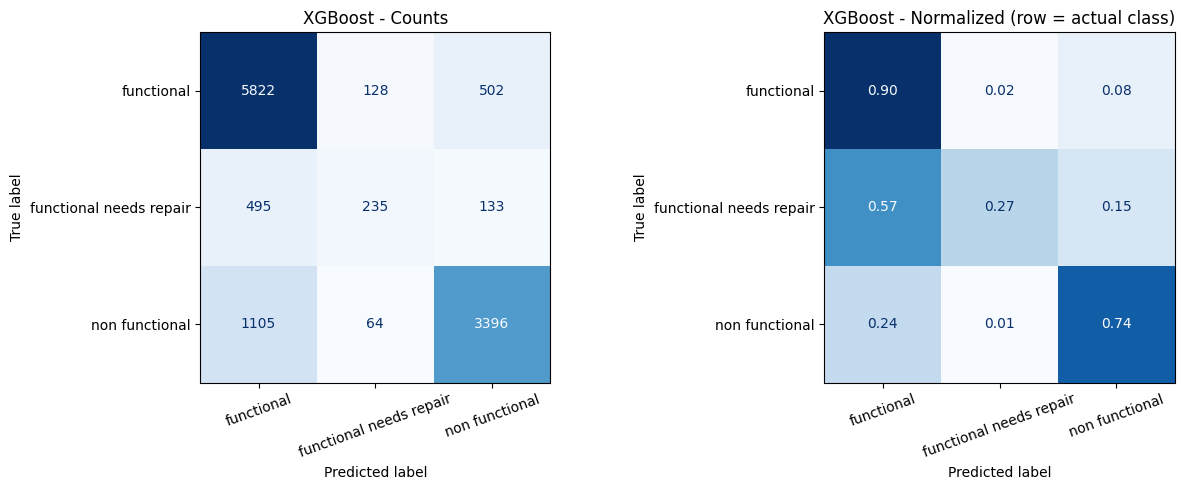

In [98]:
pred_xgb = best_xgb.predict(X_test)
evaluate('XGBoost', y_test, pred_xgb)
print('CV best (micro F2):', round(study_xgb.best_value, 4))
print('Best params:', study_xgb.best_params)
show_report('XGBoost', y_test, pred_xgb)

### 6.2 Model 2: LightGBM Optimization
Tune learning rate, tree count, `num_leaves`, `max_depth`, `min_child_samples`, subsampling, and `reg_lambda`.


In [ ]:
def lgb_factory(**p):
    return lambda: lgb.LGBMClassifier(**p, verbose=-1, device_type='cpu',random_state=SEED,n_jobs=-1)

def obj_lgb(trial):
    p = dict(learning_rate=trial.suggest_float('learning_rate', 0.02, 0.2, log=True),
             n_estimators=trial.suggest_int('n_estimators', 200, 800, step=100),
             num_leaves=trial.suggest_int('num_leaves', 20, 150),
             max_depth=trial.suggest_int('max_depth', 4, 12),
             min_child_samples=trial.suggest_int('min_child_samples', 10, 60),
             subsample=trial.suggest_float('subsample', 0.6, 1.0), subsample_freq=1,
             colsample_bytree=trial.suggest_float('colsample_bytree', 0.5, 1.0),
             reg_lambda=trial.suggest_float('reg_lambda', 0.5, 10, log=True))
    return cv_micro_f2(lgb_factory(**p))

study_lgb = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))

study_lgb.optimize(obj_lgb, n_trials=N_TRIALS)

best_lgb = Pipeline([('prep', make_preprocessor()), ('clf', lgb_factory(**study_lgb.best_params)())])
best_lgb.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('fe', ...), ('ct', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,top_n,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or esti

#### Evaluating LightGBM
Generate predictions, display classification metrics, plot multiclass confusion matrices

LightGBM               Micro F1=0.7891 Micro F2=0.7891
CV best (micro F2): 0.7904
Best params: {'learning_rate': 0.032062508293426, 'n_estimators': 600, 'num_leaves': 136, 'max_depth': 11, 'min_child_samples': 11, 'subsample': 0.6266032638729363, 'colsample_bytree': 0.9386529374270782, 'reg_lambda': 0.7249155811557549}
===== LightGBM =====
                         precision    recall  f1-score   support

             functional      0.776     0.900     0.833      6452
functional needs repair      0.540     0.268     0.358       863
         non functional      0.841     0.731     0.782      4565

               accuracy                          0.789     11880
              macro avg      0.719     0.633     0.658     11880
           weighted avg      0.784     0.789     0.779     11880



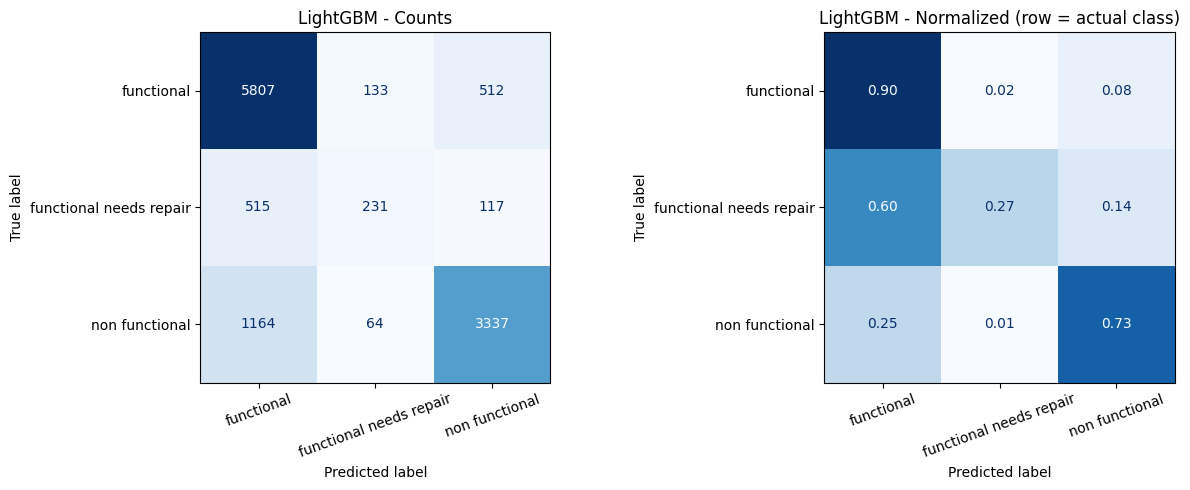

In [100]:
pred_lgb = best_lgb.predict(X_test)
evaluate('LightGBM', y_test, pred_lgb)
print('CV best (micro F2):', round(study_lgb.best_value, 4))
print('Best params:', study_lgb.best_params)
show_report('LightGBM', y_test, pred_lgb)

### 6.3 Model 3: CatBoost Optimization
Tune learning rate, symmetric tree depth, iterations, and L2 leaf regularization.


In [ ]:
def cat_factory(**p):
    return lambda: CatBoostClassifier(**p, verbose=False, task_type='GPU',random_seed=SEED)

def obj_cat(trial):
    p = dict(learning_rate=trial.suggest_float('learning_rate', 0.03, 0.2, log=True),
             depth=trial.suggest_int('depth', 4, 9),
             iterations=trial.suggest_int('iterations', 200, 800, step=100),
             l2_leaf_reg=trial.suggest_float('l2_leaf_reg', 1, 10))
    return cv_micro_f2(cat_factory(**p))

study_cat = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))

study_cat.optimize(obj_cat, n_trials=max(10, N_TRIALS // 2))

best_cat = Pipeline([('prep', make_preprocessor()), ('clf', cat_factory(**study_cat.best_params)())])
best_cat.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('fe', ...), ('ct', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,top_n,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or esti

#### Evaluating CatBoost
Generate predictions, display classification metrics, plot multiclass confusion matrices

CatBoost               Micro F1=0.7952 Micro F2=0.7952
CV best (micro F2): 0.79
Best params: {'learning_rate': 0.16539041076612807, 'depth': 9, 'iterations': 800, 'l2_leaf_reg': 2.411294460650672}
===== CatBoost =====
                         precision    recall  f1-score   support

             functional      0.789     0.894     0.838      6452
functional needs repair      0.546     0.301     0.388       863
         non functional      0.835     0.750     0.790      4565

               accuracy                          0.795     11880
              macro avg      0.723     0.648     0.672     11880
           weighted avg      0.789     0.795     0.787     11880



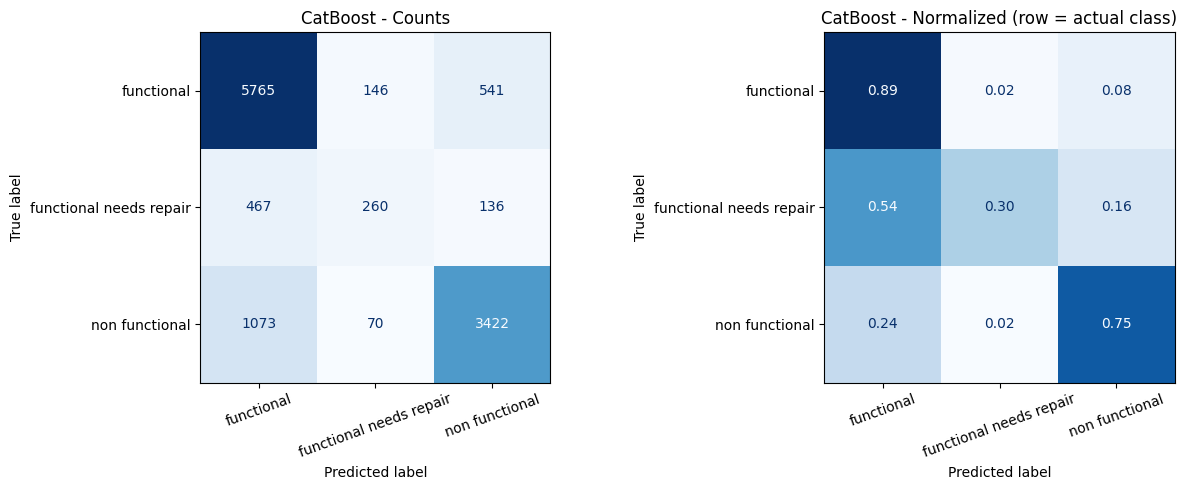

In [102]:
pred_cat = best_cat.predict(X_test).ravel()
evaluate('CatBoost', y_test, pred_cat)
print('CV best (micro F2):', round(study_cat.best_value, 4))
print('Best params:', study_cat.best_params)
show_report('CatBoost', y_test, pred_cat)

### 6.4 Model 4: Random Forest Optimization (Scikit-Learn)
Tune tree estimators, maximum depth, split criteria, minimum leaf samples, and maximum feature sampling ratios.


In [ ]:
def rf_factory(**p):
    return lambda: RandomForestClassifier(**p, random_state=SEED, n_jobs=-1)

def obj_rf(trial):
    p = dict(n_estimators=trial.suggest_int('n_estimators', 200, 500, step=100),
             max_depth=trial.suggest_int('max_depth', 10, 30),
             min_samples_split=trial.suggest_int('min_samples_split', 2, 10),
             min_samples_leaf=trial.suggest_int('min_samples_leaf', 1, 5),
             max_features=trial.suggest_categorical('max_features', ['sqrt', 0.3, 0.5]))
    return cv_micro_f2(rf_factory(**p))

study_rf = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study_rf.optimize(obj_rf, n_trials=max(10, N_TRIALS // 2))

best_rf = Pipeline([('prep', make_preprocessor()), ('clf', rf_factory(**study_rf.best_params)())])
best_rf.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('fe', ...), ('ct', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,top_n,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or esti

#### Evaluating Random Forest (Scikit-Learn)
Generate predictions, display classification metrics, plot multiclass confusion matrices

Random Forest (Scikit-Learn) Micro F1=0.7951 Micro F2=0.7951
CV best (micro F2): 0.7924
Best params: {'n_estimators': 400, 'max_depth': 23, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
===== Random Forest (Scikit-Learn) =====
                         precision    recall  f1-score   support

             functional      0.777     0.913     0.839      6452
functional needs repair      0.587     0.247     0.347       863
         non functional      0.850     0.732     0.787      4565

               accuracy                          0.795     11880
              macro avg      0.738     0.631     0.658     11880
           weighted avg      0.791     0.795     0.783     11880



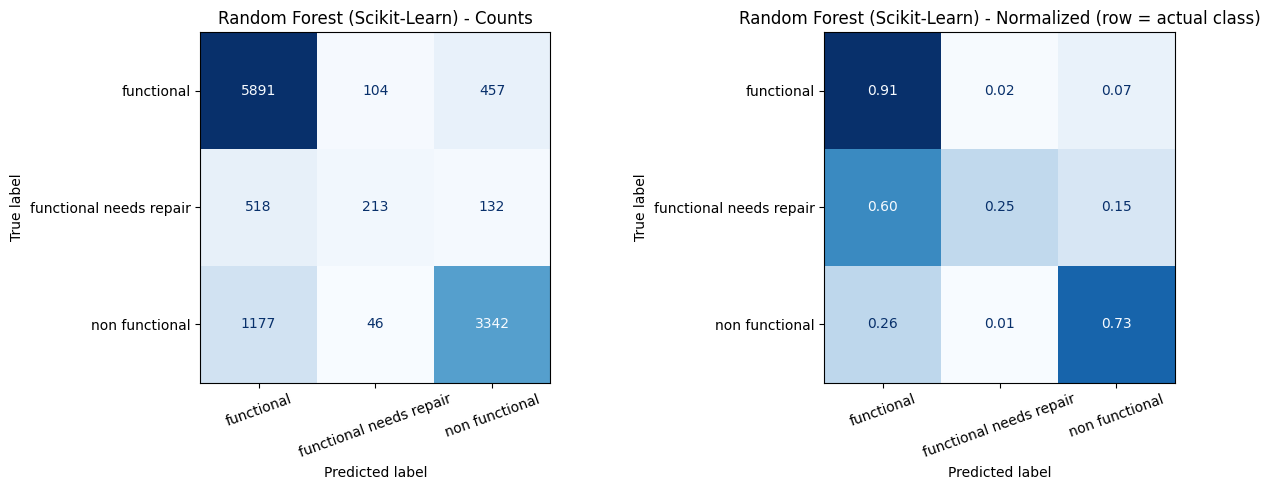

In [104]:
pred_rf = best_rf.predict(X_test)
evaluate('Random Forest (Scikit-Learn)', y_test, pred_rf)
print('CV best (micro F2):', round(study_rf.best_value, 4))
print('Best params:', study_rf.best_params)
show_report('Random Forest (Scikit-Learn)', y_test, pred_rf)

### 6.5 Model 5: Random Forest Optimization (XGBoost)
Tune tree estimators, maximum depth, split criteria, minimum leaf samples, and maximum feature sampling ratios.

In [ ]:
# Check XGBoost version and set appropriate parameters for GPU usage
def get_xgb_cuda_kwargs():
    from packaging import version
    if version.parse(xgb.__version__) >= version.parse("2.0.0"):
        return {"device": "cuda"}
    return {"tree_method": "gpu_hist"}

CUDA_KWARGS = get_xgb_cuda_kwargs()

# Factory function to create XGBClassifier with given hyperparameters and GPU settings
def xgb_factory(**p):
    return lambda: XGBClassifier(
        **p,
        **CUDA_KWARGS,
        random_state=SEED,
        eval_metric='mlogloss'
    )

def obj_xgb(trial):
    p = dict(
        n_estimators=trial.suggest_int('n_estimators', 200, 600, step=100),
        learning_rate=trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        max_depth=trial.suggest_int('max_depth', 3, 10),
        min_child_weight=trial.suggest_int('min_child_weight', 1, 10),
        subsample=trial.suggest_float('subsample', 0.6, 1.0, step=0.1),
        colsample_bytree=trial.suggest_float('colsample_bytree', 0.5, 1.0, step=0.1),
        reg_alpha=trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
    )
    return cv_micro_f2(xgb_factory(**p))

# Create an Optuna study for XGBoost hyperparameter optimization
study_xgb = optuna.create_study(
    direction='maximize', 
    sampler=optuna.samplers.TPESampler(seed=SEED)
)
study_xgb.optimize(obj_xgb, n_trials=max(10, N_TRIALS // 2))

# Train the best XGBoost model using the optimized hyperparameters
best_xgbrf = Pipeline([
    ('prep', make_preprocessor()),
    ('clf', xgb_factory(**study_xgb.best_params)())
])
best_xgbrf.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('fe', ...), ('ct', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,top_n,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or esti

#### Evaluating Random Forest (XGBoost)
Generate predictions, display classification metrics, plot multiclass confusion matrices

Random Forest (XGBoost) Micro F1=0.7958 Micro F2=0.7958
CV best (micro F2): 0.7903
Best params: {'n_estimators': 500, 'learning_rate': 0.08026013725738236, 'max_depth': 10, 'min_child_weight': 7, 'subsample': 0.7, 'colsample_bytree': 0.7, 'reg_alpha': 0.045109458722977086, 'reg_lambda': 3.3963753137050916}
===== Random Forest (XGBoost) =====
                         precision    recall  f1-score   support

             functional      0.786     0.898     0.838      6452
functional needs repair      0.543     0.278     0.368       863
         non functional      0.840     0.750     0.793      4565

               accuracy                          0.796     11880
              macro avg      0.723     0.642     0.666     11880
           weighted avg      0.789     0.796     0.787     11880



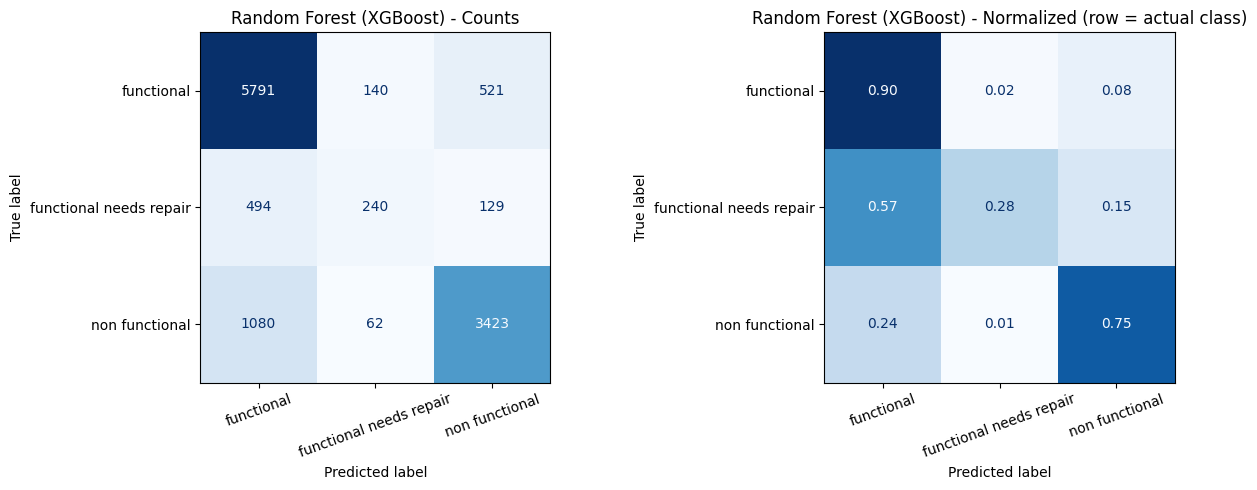

In [106]:
pred_xgbrf = best_xgbrf.predict(X_test)
evaluate('Random Forest (XGBoost)', y_test, pred_xgbrf)
print('CV best (micro F2):', round(study_xgb.best_value, 4))
print('Best params:', study_xgb.best_params)
show_report('Random Forest (XGBoost)', y_test, pred_xgbrf)

## 7. Best Model Selection, Full Refit & Deployment Artifact

### 7.1 Automated Selection & Packaging
Rank the holdout results, select the winning pipeline, and refit it on all labeled data for deployment.
The bundle at `models/best_waterpump_model.pkl` contains the fitted pipeline, label encoder, expected feature schema, selection metrics, and runtime versions.
Include `feature_engineer.py` in the deployment package and use compatible Python, scikit-learn, and XGBoost versions when loading the pickle.
Only load pickle artifacts from trusted sources.


In [124]:
res = pd.DataFrame(results).T.sort_values('Micro F2', ascending=False).round(4)
display(res)

best_name = res.index[0]
print('Best:', best_name)

single = {
    'XGBoost': best_xgb,
    'LightGBM': best_lgb,
    'CatBoost': best_cat,
    'Random Forest (Scikit-Learn)': best_rf,
    'Random Forest (XGBoost)': best_xgbrf,
    'Logistic Regression': log_pipe,
}

# Guard against key naming mismatches between model registry and leaderboard
if best_name not in single:
    match = next((k for k in single if k.replace(' ', '') == best_name.replace(' ', '')), None)
    if match is None:
        raise KeyError(f"Best model '{best_name}' not found in single registry.")
    best_name = match

chosen, kind = {best_name: single[best_name]}, 'single'

,Micro F1,Micro F2
Random Forest (XGBoost),0.7958,0.7958
XGBoost,0.7957,0.7957
CatBoost,0.7952,0.7952
Random Forest (Scikit-Learn),0.7951,0.7951
LightGBM,0.7891,0.7891
Logistic Regression,0.7375,0.7375
Dummy,0.3351,0.3351


Best: Random Forest (XGBoost)


In [ ]:
# Refit the selected estimator on all labeled data for deployment
final_models = {}
for name, estimator in chosen.items():
    fitted_estimator = clone(estimator)
    fitted_estimator.fit(X, y)
    final_models[name] = fitted_estimator

# Persist a self-describing bundle; do not depend on stale notebook variables
deployment_bundle = {
    'artifact_version': 1,
    'model_name': best_name,
    'model_kind': kind,
    'models': final_models,
    'label_encoder': le,
    'feature_columns': X.columns.tolist(),
    'feature_dtypes': X.dtypes.astype(str).to_dict(),
    'labels': le.classes_.tolist(),
    'metrics': {key: float(value) for key, value in res.loc[best_name].items()},
    'runtime_versions': {
        'python': platform.python_version(),
        'scikit_learn': sklearn.__version__,
        'xgboost': xgb.__version__,
    },
}

os.makedirs('models', exist_ok=True)
with open('models/best_waterpump_model.pkl', 'wb') as artifact_file:
    pickle.dump(deployment_bundle, artifact_file, protocol=pickle.HIGHEST_PROTOCOL)

print(f"Saved {best_name} (Micro F2={deployment_bundle['metrics']['Micro F2']:.4f})")
print('Artifact: models/best_waterpump_model.pkl')

Saved Random Forest (XGBoost) (Micro F2=0.7958)
Artifact: models/best_waterpump_model.pkl


### 7.2 Immediate Inference Smoke Test
Verify that the saved bundle correctly loads and predicts original text class labels on unseen feature vectors using `predict_labels()`.


In [127]:
# Load the serialized artifact, then validate its metadata and inference path
artifact_path = 'models/best_waterpump_model.pkl'
with open(artifact_path, 'rb') as artifact_file:
    loaded_bundle = pickle.load(artifact_file)

assert loaded_bundle['artifact_version'] == 1
assert loaded_bundle['model_name'] == best_name
assert loaded_bundle['feature_columns'] == X.columns.tolist()

sample = X_test.loc[:, loaded_bundle['feature_columns']].head()
predicted_labels = predict_labels(loaded_bundle, sample)
assert len(predicted_labels) == len(sample)
assert set(predicted_labels).issubset(set(loaded_bundle['labels']))

print(f"Loaded {loaded_bundle['model_name']} from {artifact_path}")
print('Predicted labels:', predicted_labels)
print('Runtime versions:', loaded_bundle['runtime_versions'])

Loaded Random Forest (XGBoost) from models/best_waterpump_model.pkl
Predicted labels: ['non functional' 'functional' 'functional' 'functional' 'non functional']
Runtime versions: {'python': '3.13.5', 'scikit_learn': '1.8.0', 'xgboost': '3.4.1'}


## 8. Comprehensive Benchmark Comparison

We consolidate holdout predictions across all evaluated model paradigms into a unified comparative leaderboard and bar chart.


In [118]:
preds = {
    'Dummy': dummy.predict(X_test),
    'Logistic Regression': pred_log,
    'XGBoost': pred_xgb,
    'LightGBM': pred_lgb,
    'CatBoost': pred_cat,
    'Random Forest (By XGBoost)': pred_xgbrf,
    'Random Forest (Scikit-learn)': pred_rf
}

rows = {name: {'Micro F1': f1_score(y_test, p, average='micro'),
               'Micro F2': fbeta_score(y_test, p, beta=2, average='micro')}
        for name, p in preds.items()}

cmp = pd.DataFrame(rows).T.sort_values('Micro F2', ascending=False)
display(cmp.round(4))

,Micro F1,Micro F2
Random Forest (By XGBoost),0.7958,0.7958
XGBoost,0.7957,0.7957
CatBoost,0.7952,0.7952
Random Forest (Scikit-learn),0.7951,0.7951
LightGBM,0.7891,0.7891
Logistic Regression,0.7375,0.7375
Dummy,0.3351,0.3351


## 9 Overfitting & Underfitting Diagnostics

We check whether each tuned model generalizes or merely memorizes the training data by comparing performance on data it has seen against data it has not. Four complementary views are used:

1. **Hold-out gap**: train vs. test micro/macro F1 for every model.
2. **Cross-validation gap**: 5-fold CV with `return_train_score=True`, to confirm the gap is stable rather than an artifact of one split.
3. **Learning curve**: whether validation score is still improving as training data grows, which separates a data limit from a model limit.
4. **Per-class recall gap**: train vs. test recall, to see whether the minority class `functional needs repair` is where the model overfits most.

In [ ]:
models = {
    'Logistic Regression': log_pipe,
    'XGBoost': best_xgb,
    'LightGBM': best_lgb,
    'CatBoost': best_cat,
    'Random Forest (Scikit-learn)': best_rf,
    'Random Forest (XGBoost)': best_xgbrf
}

# Evaluate each model with learning curves (train vs validation) and summarize results
GAP_OVERFIT = 0.05    # train - validation > 0.05 -> Probably overfit
LOW_SCORE   = 0.75    # validation lower than this and gap <= 0.05 -> Probably underfit
 
def diagnose(train_s, val_s):
    gap = train_s - val_s
    if gap > GAP_OVERFIT:
        return 'Probably Overfitting'
    if val_s < LOW_SCORE and gap <= GAP_OVERFIT:
        return 'Probably Underfitting (or high bias)'
    return 'Probably Good fit'

In [111]:
# Comparing Train vs Test performance for all models
rows = []
for name, m in models.items():
    p_tr, p_te = m.predict(X_train), m.predict(X_test)
    tr_f1, te_f1 = f1_score(y_train, p_tr, average='micro'), f1_score(y_test, p_test := p_te, average='micro')
    tr_mac, te_mac = f1_score(y_train, p_tr, average='macro'), f1_score(y_test, p_te, average='macro')
    rows.append({
        'Model': name,
        'Train Micro F1': tr_f1, 'Test Micro F1': te_f1, 'Gap (micro)': tr_f1 - te_f1,
        'Train Macro F1': tr_mac, 'Test Macro F1': te_mac, 'Gap (macro)': tr_mac - te_mac,
        'Diagnosis': diagnose(tr_f1, te_f1),
    })
holdout = pd.DataFrame(rows).set_index('Model').round(4)
print('===== Train vs Test =====')
display(holdout)

===== Train vs Test =====


,Train Micro F1,Test Micro F1,Gap (micro),Train Macro F1,Test Macro F1,Gap (macro),Diagnosis
Model,,,,,,,
Logistic Regression,0.7402,0.7375,0.0027,0.5623,0.5541,0.0082,Probably Underfitting (or high bias)
XGBoost,0.8678,0.7957,0.0721,0.7877,0.6646,0.1231,Probably Overfitting
LightGBM,0.8696,0.7891,0.0805,0.7966,0.6578,0.1388,Probably Overfitting
CatBoost,0.8765,0.7952,0.0813,0.8075,0.6721,0.1354,Probably Overfitting
Random Forest (Scikit-learn),0.8747,0.7951,0.0796,0.7844,0.6578,0.1266,Probably Overfitting
Random Forest (XGBoost),0.8679,0.7958,0.0721,0.7889,0.6662,0.1227,Probably Overfitting


===== 2) 5-fold CV (train vs validation) =====


,CV Train Micro F1,CV Val Micro F1,Val Std,Gap,CV Train Macro F1,CV Val Macro F1,Diagnosis
Model,,,,,,,
Logistic Regression,0.7396,0.7369,0.0031,0.0026,0.5576,0.5541,Probably Underfitting (or high bias)
XGBoost,0.8727,0.7920,0.0027,0.0807,0.7967,0.6659,Probably Overfitting
LightGBM,0.8771,0.7900,0.0021,0.0871,0.8099,0.6608,Probably Overfitting
CatBoost,0.8850,0.7915,0.0024,0.0935,0.8221,0.6681,Probably Overfitting
Random Forest (Scikit-learn),0.8781,0.7938,0.0029,0.0842,0.7909,0.6577,Probably Overfitting
Random Forest (XGBoost),0.8740,0.7910,0.0023,0.0829,0.7994,0.6661,Probably Overfitting


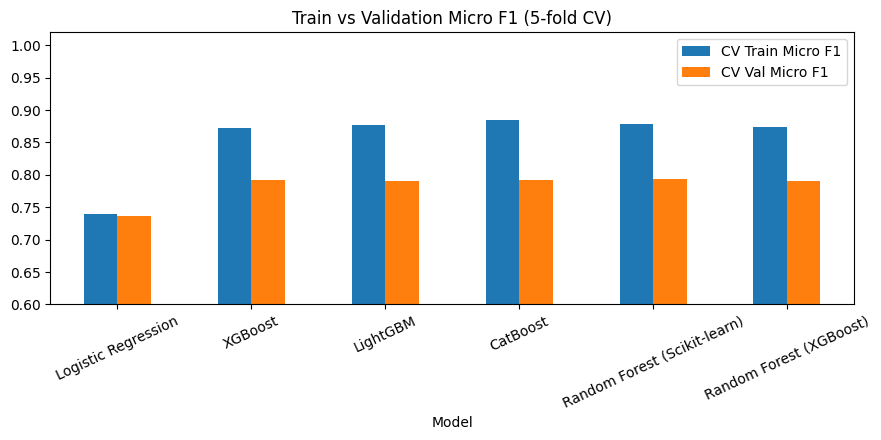

In [112]:
# Cross-validation with train score (check stability of results)

skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for name, m in models.items():
    cv = cross_validate(clone(m), X_train, y_train, cv=skf5,
                        scoring={'f1_micro': 'f1_micro', 'f1_macro': 'f1_macro'},
                        return_train_score=True, n_jobs=1)
    tr, va = cv['train_f1_micro'], cv['test_f1_micro']
    cv_rows.append({
        'Model': name,
        'CV Train Micro F1': tr.mean(),
        'CV Val Micro F1': va.mean(), 'Val Std': va.std(),
        'Gap': tr.mean() - va.mean(),
        'CV Train Macro F1': cv['train_f1_macro'].mean(),
        'CV Val Macro F1': cv['test_f1_macro'].mean(),
        'Diagnosis': diagnose(tr.mean(), va.mean()),
    })
cv_df = pd.DataFrame(cv_rows).set_index('Model').round(4)
print('===== 2) 5-fold CV (train vs validation) =====')
display(cv_df)
 
# graph comparing Train vs Val per model
ax = cv_df[['CV Train Micro F1', 'CV Val Micro F1']].plot(kind='bar', figsize=(9, 4.5), rot=25)
ax.set_ylim(0.6, 1.02)
ax.set_title('Train vs Validation Micro F1 (5-fold CV)')
plt.tight_layout(); plt.show()

===== 3) Learning curve (all models) =====


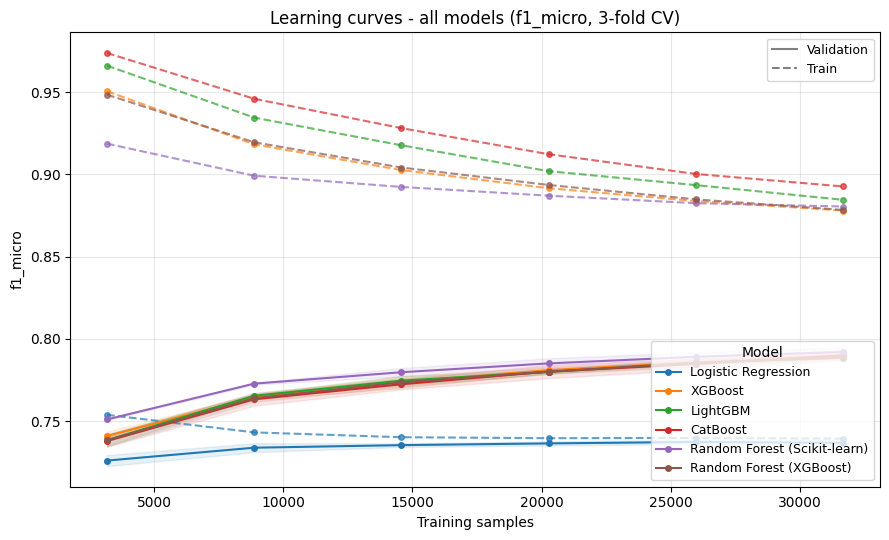

At maximum training size (Gap = Train - Validation, Val gain = val at the last step):


,Train,Validation,Gap,Val gain (last step)
Model,,,,
Logistic Regression,0.7393,0.7367,0.0026,-0.0005
XGBoost,0.8780,0.7901,0.0879,0.0044
LightGBM,0.8845,0.7886,0.0959,0.0031
CatBoost,0.8926,0.7899,0.1028,0.0052
Random Forest (Scikit-learn),0.8804,0.7920,0.0884,0.0030
Random Forest (XGBoost),0.8784,0.7885,0.0898,0.0031


In [113]:
# Learning Curve: every model in one graph
# line = Validation, dashed = Train (same color per model)

def plot_learning_curves_all(models, scoring='f1_micro', cv=3, n_points=6):
    skf = StratifiedKFold(cv, shuffle=True, random_state=SEED)
    colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    fig, ax = plt.subplots(figsize=(9, 5.5))
    summary = []

    for i, (name, m) in enumerate(models.items()):
        sizes, tr_sc, va_sc = learning_curve(
            clone(m), X_train, y_train, cv=skf,
            train_sizes=np.linspace(0.1, 1.0, n_points), scoring=scoring,
            n_jobs=1, shuffle=True, random_state=SEED)
        tr_m, va_m = tr_sc.mean(1), va_sc.mean(1)
        va_s = va_sc.std(1)
        c = colors[i % len(colors)]

        ax.plot(sizes, tr_m, '--', marker='o', ms=4, color=c, alpha=0.7)
        ax.plot(sizes, va_m, '-',  marker='o', ms=4, color=c, label=name)
        ax.fill_between(sizes, va_m - va_s, va_m + va_s, color=c, alpha=0.10)

        summary.append({'Model': name,
                        'Train': tr_m[-1], 'Validation': va_m[-1],
                        'Gap': tr_m[-1] - va_m[-1],
                        'Val gain (last step)': va_m[-1] - va_m[-2]})

    # legend 2 sets: model (color) and line type (train/val)
    from matplotlib.lines import Line2D
    leg1 = ax.legend(title='Model', loc='lower right', fontsize=9)
    ax.add_artist(leg1)
    ax.legend(handles=[Line2D([0], [0], color='gray', ls='-',  label='Validation'),
                       Line2D([0], [0], color='gray', ls='--', label='Train')],
              loc='upper right', fontsize=9)

    ax.set_title(f'Learning curves - all models ({scoring}, {cv}-fold CV)')
    ax.set_xlabel('Training samples'); ax.set_ylabel(scoring)
    ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    out = pd.DataFrame(summary).set_index('Model').round(4)
    print('At maximum training size (Gap = Train - Validation, '
          'Val gain = val at the last step):')
    display(out)
    return out

print('===== 3) Learning curve (all models) =====')
lc_df = plot_learning_curves_all(models)

In [114]:
# Recall with respect to each class (Train vs Test) to check for minority class performance
print('===== 4) Recall to each class (Train vs Test) =====')
cls_rows = []
for name, m in models.items():
    r_tr = recall_score(y_train, m.predict(X_train), average=None)
    r_te = recall_score(y_test, m.predict(X_test), average=None)
    for i, c in enumerate(le.classes_):
        cls_rows.append({'Model': name, 'Class': c, 'Train Recall': r_tr[i],
                         'Test Recall': r_te[i], 'Gap': r_tr[i] - r_te[i]})
display(pd.DataFrame(cls_rows).round(4))

===== 4) Recall to each class (Train vs Test) =====


,Model,Class,Train Recall,Test Recall,Gap
0,Logistic Regression,functional,0.8925,0.8893,0.0032
1,Logistic Regression,functional needs repair,0.1080,0.0950,0.0130
2,Logistic Regression,non functional,0.6446,0.6445,0.0001
3,XGBoost,functional,0.9495,0.9024,0.0472
4,XGBoost,functional needs repair,0.4789,0.2723,0.2066
5,XGBoost,non functional,0.8258,0.7439,0.0819
6,LightGBM,functional,0.9539,0.9000,0.0539
7,LightGBM,functional needs repair,0.5067,0.2677,0.2390
8,LightGBM,non functional,0.8192,0.7310,0.0882
9,CatBoost,functional,0.9487,0.8935,0.0552


In [115]:
# Summarize hold-out vs CV gap and diagnosis
print('===== Summary =====')
for name in models:
    h, c = holdout.loc[name], cv_df.loc[name]
    print(f"{name:20s} | hold-out gap={h['Gap (micro)']:.3f} -> {h['Diagnosis']:<28s} "
          f"| CV gap={c['Gap']:.3f} -> {c['Diagnosis']}")

===== Summary =====
Logistic Regression  | hold-out gap=0.003 -> Probably Underfitting (or high bias) | CV gap=0.003 -> Probably Underfitting (or high bias)
XGBoost              | hold-out gap=0.072 -> Probably Overfitting         | CV gap=0.081 -> Probably Overfitting
LightGBM             | hold-out gap=0.081 -> Probably Overfitting         | CV gap=0.087 -> Probably Overfitting
CatBoost             | hold-out gap=0.081 -> Probably Overfitting         | CV gap=0.093 -> Probably Overfitting
Random Forest (Scikit-learn) | hold-out gap=0.080 -> Probably Overfitting         | CV gap=0.084 -> Probably Overfitting
Random Forest (XGBoost) | hold-out gap=0.072 -> Probably Overfitting         | CV gap=0.083 -> Probably Overfitting
